# Bias and variance in polynomial regression

We will study how the degree of a polynomial affects its predictions when the training data change.

Our true function is
$$
f(x)=0.5x+2x^2+2.
$$
Each observation contains measurement noise:
$$
y_i=f(x_i)+\epsilon_i,\qquad
\epsilon_i\sim{N}(0,\sigma_\epsilon^2).
$$
The inputs are sampled independently and uniformly from $[-1,1]$. The noise terms are independent of the inputs and of one another. We use $n=50$ observations per training set and $\sigma_\epsilon=0.5$.

First, we study predictions at one fixed input, $x_{\mathrm{test}}=1.2$. This tests generalization by **extrapolation**, because the test input is outside the training interval. The true response there is $f(x_{\mathrm{test}})$; a noisy test observation is $y_{\mathrm{test}}=f(x_{\mathrm{test}})+\epsilon_{\mathrm{test}}$, with independent noise.

Later, we will use 100 observations per training set and noise standard deviation 1, and average errors over test inputs sampled from $[0.5,1.5)$. Some of those test inputs also require extrapolation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Use 8-point text everywhere in the plots.
fntsz = 8
plt.rcParams.update({
    'font.size': fntsz,
    'axes.titlesize': fntsz,
    'axes.labelsize': fntsz,
    'xtick.labelsize': fntsz,
    'ytick.labelsize': fntsz,
    'legend.fontsize': fntsz,
    'legend.title_fontsize': fntsz,
    'figure.titlesize': fntsz,
    'lines.linewidth': 1,
    'lines.markersize': 3,
})

# US Letter is 8.5 inches wide: each plotting area is 1.7 inches wide.
panel_width = 8.5 / 5
panel_height = panel_width

# Keep this formatting helper separate from the regression calculations.
def plot_panels(nrows=1, ncols=1, sharex=False, sharey=False):
    # Add space for labels, titles, gaps, and a legend below the panels.
    fig_width = ncols * panel_width + 0.7 + (ncols - 1) * 0.55
    fig_height = nrows * panel_height + 2.15 + (nrows - 1) * 0.9
    fig, axs = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height),
                            sharex=sharex, sharey=sharey)
    # Fixed margins preserve the physical width of each plotting area.
    fig.subplots_adjust(
        left=0.5 / fig_width, right=1 - 0.2 / fig_width,
        bottom=1.5 / fig_height, top=1 - 0.65 / fig_height,
        wspace=0.55 / panel_width, hspace=0.9 / panel_height,
    )
    return fig, axs


# Make the random examples repeatable when we run from the top.
np.random.seed(42)



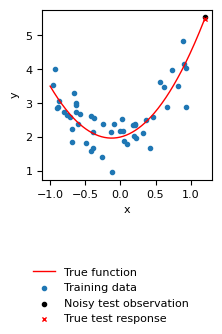

In [2]:
# Define the true function that generates the data.
def f(x):
  return .5 * x + 2 * x**2 + 2


n = 50                 # Number of observations in each training set.
x_max = 1              # Training inputs lie between -1 and 1.
sigma_epsilon = 0.5    # Standard deviation of the measurement noise.

# Generate one training set.
x_train = np.random.uniform(-x_max,x_max,n)
noise = np.random.normal(0,sigma_epsilon,n)
y_train = f(x_train)+noise

# Generate an independent noisy observation at the test input.
x_test = 1.2
y_true = f(x_test)
y_test = y_true + np.random.normal(0,sigma_epsilon)

# Use a smooth grid to draw curves, including the test input.
x_plot = np.linspace(-x_max, x_test, 200)

fig, ax = plot_panels()
plt.plot(x_plot, f(x_plot), color='red', label='True function')
plt.scatter(x_train, y_train, label='Training data')
plt.scatter(x_test, y_test, color='black', label='Noisy test observation')
plt.scatter(x_test, y_true, color='red', marker='x', label='True test response')
plt.xlabel('x')
plt.ylabel('y')
fig.legend(loc='lower center', frameon=False)
plt.show()


## Fit polynomials to several training sets

For degree $d$, our model is
$$
\hat{f}_{d,D}(x)=w_0+w_1x+\cdots+w_dx^d.
$$
There are $d+1$ coefficients, including the intercept $w_0$. The subscript $D$ reminds us that the fitted coefficients depend on the training dataset.

We choose the coefficients by minimizing the sum of squared training errors. Under our independent Gaussian noise model with a common variance, this is also maximum likelihood estimation.

We use `np.polyfit(x_train, y_train, d)` to fit a polynomial. It returns coefficients in the order $[w_d,\ldots,w_1,w_0]$. We use `np.polyval(w, x)` to evaluate that polynomial.

We compare degrees $d=0,1,2,3,4,5$. Each of seven experiments uses a fresh training set of 50 observations. Within an experiment, all degrees use the same training set so that their predictions are easy to compare.

The first figure compares degrees within each experiment. The second compares fitted curves across experiments for each degree. Six experiments illustrate variability; later we will use more experiments to estimate bias and variance.


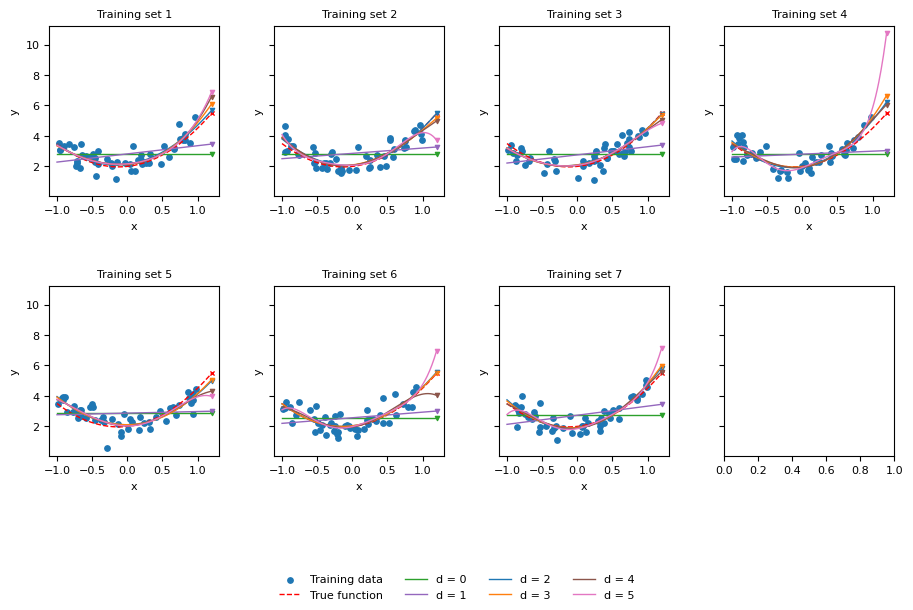

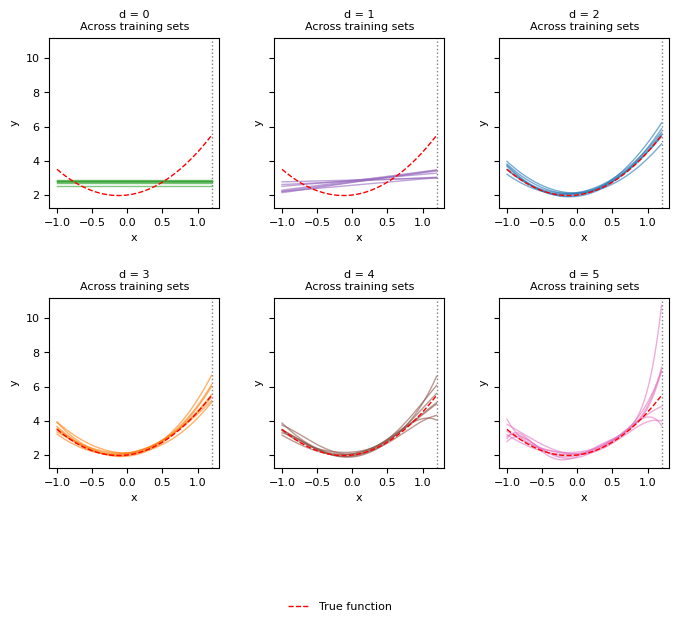

In [4]:
d_arr = [0, 1, 2, 3, 4, 5]
colors = ['tab:green', 'tab:purple', 'tab:blue', 'tab:orange', 'tab:brown', 'tab:pink']
n_examples = 7
all_weights = []       # Each entry will contain the six fits for one dataset.

fig, axs = plot_panels(2, 4, sharey=True)

for r in range(n_examples):
    # Generate a fresh training set for this experiment.
    x_train = np.random.uniform(-x_max,x_max,n)
    y_train = f(x_train)+np.random.normal(0,sigma_epsilon,n)

    # Select the next panel, reading the panels in row order.
    ax = axs.flat[r]
    ax.scatter(x_train, y_train, s=15, label='Training data')
    ax.plot(x_plot, f(x_plot), 'r--', label='True function')
    ax.scatter(x_test, y_true, color='red', marker='x')

    weights = []
    for k in range(len(d_arr)):
      d = d_arr[k]
      w = np.polyfit(x_train,y_train,d) # Fit degree d to this dataset.
      weights.append(w)                 # Save the coefficients.
      y_fit = np.polyval(w,x_plot)      # Evaluate the fitted curve.
      prediction = np.polyval(w,x_test) # Predict at the test input.
      ax.plot(x_plot, y_fit, color=colors[k], label=f'd = {d}')
      ax.scatter(x_test, prediction, color=colors[k], marker='v')

    all_weights.append(weights)
    ax.set_title(f'Training set {r + 1}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
plt.show()

# Compare the fitted curves across training sets, one degree per panel.
fig, axs = plot_panels(2, 3, sharey=True)
for k in range(len(d_arr)):
    ax = axs.flat[k]
    for r in range(n_examples):
        w = all_weights[r][k]
        ax.plot(x_plot, np.polyval(w, x_plot), color=colors[k], alpha=0.6)
    ax.plot(x_plot, f(x_plot), 'r--', label='True function')
    ax.axvline(x_test, color='gray', linestyle=':')
    ax.set_title(f'd = {d_arr[k]}\nAcross training sets')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()


## Estimate bias and variance at a fixed input

Imagine repeatedly drawing a new independent training dataset $D_r$ ("experiment"), for $r=1,\ldots,M$ experiments, and fitting a degree-$d$ polynomial to each experiment: $\hat f_{d,D_r}$. At a fixed input $x$, define the mean prediction
$$
\mu_d(x)=\mathbb{E}_D[\hat f_{d,D}(x)]
$$
The **bias** is the difference between the mean prediction and the true response:
$$
\operatorname{Bias}_d(x)=\mu_d(x)-f(x).
$$
The **variance** measures how much predictions change across training datasets:
$$
\operatorname{Var}_d(x)=\mathbb{E}_D[(\hat f_{d,D}(x)-\mu_d(x))^2].
$$
We estimate these quantities using $M$ independently generated training datasets:
$$
\bar f_d(x)=\frac{1}{M}\sum_{r=1}^M\hat f_{d,D_r}(x),
$$
$$
\widehat{\operatorname{Bias}}_d(x)^2=(\bar f_d(x)-f(x))^2,
\qquad
\widehat{\operatorname{Var}}_d(x)=\frac{1}{M}\sum_{r=1}^M(\hat f_{d,D_r}(x)-\bar f_d(x))^2.
$$
These are finite-simulation estimates. In particular, estimated squared bias may be positive even when the population bias is zero.

For an independent test observation $y=f(x)+\epsilon$ with zero-mean noise of variance $\sigma_\epsilon^2$, the expected squared prediction error is
$$
\mathbb{E}_{D,\epsilon}[(y-\hat f_{d,D}(x))^2]
=\operatorname{Bias}_d(x)^2+\operatorname{Var}_d(x)+\sigma_\epsilon^2.
$$
The last term is **irreducible noise**. We compare the mean prediction with $f(x)$ when calculating bias, rather than with a single noisy observation $y$.

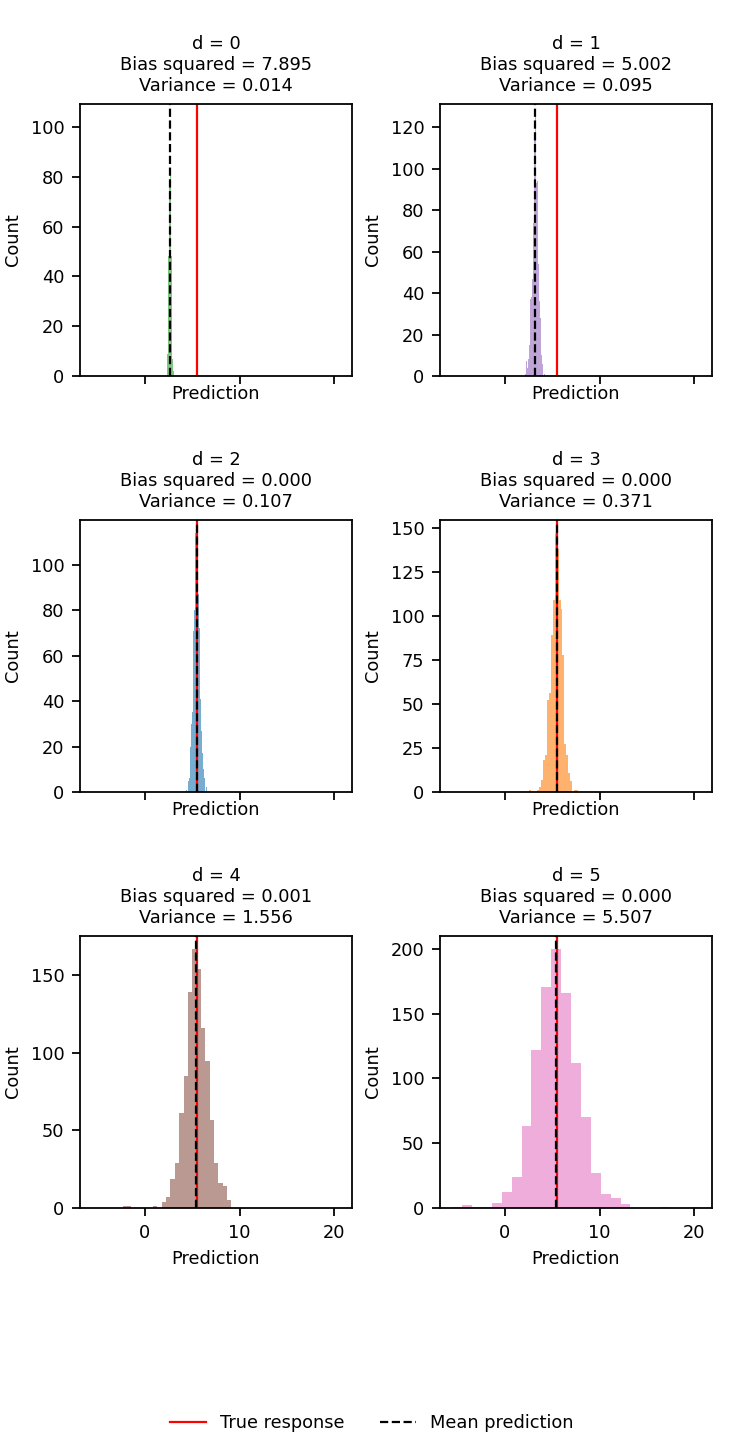

In [ ]:
n_exp = 1000

# Rows correspond to degrees; columns correspond to training datasets.


for r in range(n_exp):
    # Use the same fresh training set for all degrees in this experiment.
    x_train = np.random.uniform(-x_max, x_max, n)
    y_train = f(x_train) + np.random.normal(0, sigma_epsilon, n)

    for k in range(len(d_arr)):


# Average across training datasets, separately for each degree.


# Show how predictions vary when we change the training data.
fig, axs = plot_panels(3, 2, sharex=True)
for k in range(len(d_arr)):
    ax = axs.flat[k]
    ax.hist(y_hat_test[k], bins=25, color=colors[k], alpha=0.6)
    ax.axvline(f(x_test), color='red', label='True response')
    ax.axvline(mean_prediction[k], color='black', linestyle='--',
               label='Mean prediction')
    ax.set_title(f'd = {d_arr[k]}\nBias squared = {bias_squared[k]:.3f}'
                 f'\nVariance = {variance[k]:.3f}')
    ax.set_xlabel('Prediction')
    ax.set_ylabel('Count')

handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()


## Interpret the results

Low-degree polynomials can underfit the true function. Their mean prediction may be far from the truth, even if their predictions vary little across training sets.

Our true function is quadratic, so degree 2 can already represent it exactly. With independent zero-mean noise and a full-rank design, least-squares fits of degree 2 or greater have zero population bias, provided the relevant expectations exist. Estimated squared bias can still be positive because we use finitely many experiments.

Extra polynomial terms can increase variance without improving population bias in this example. Extrapolation can make that variability especially large.

Bias and variance do not have to change monotonically in every problem. We will inspect the measured curves rather than assume their shapes.

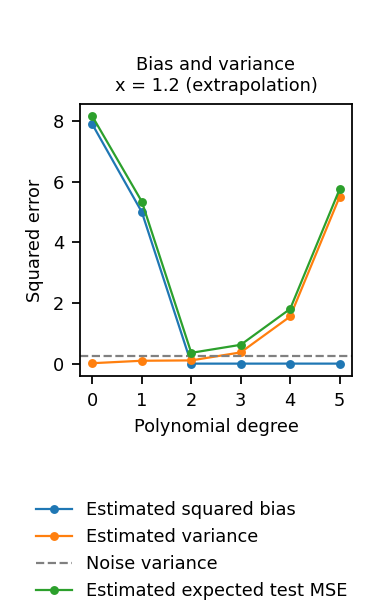

In [ ]:
# Combine the three components of expected squared prediction error.


fig, ax = plot_panels()
plt.plot(d_arr, bias_squared, 'o-', label='Estimated squared bias')
plt.plot(d_arr, variance, 'o-', label='Estimated variance')
plt.axhline(noise_variance, color='gray', linestyle='--', label='Noise variance')
plt.plot(d_arr, expected_test_mse, 'o-', label='Estimated expected test MSE')
plt.xticks(d_arr)
plt.xlabel('Polynomial degree')
plt.ylabel('Squared error')
plt.title(f'Bias and variance\nx = {x_test} (extrapolation)')
fig.legend(loc='lower center', frameon=False)
plt.show()

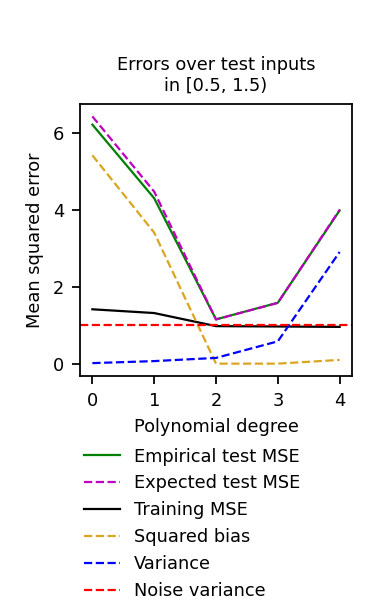

In [ ]:
# Average over the original test interval, including extrapolation.
np.random.seed(1)      # Make this final experiment repeatable on its own.

# Use the same quadratic as in the first part of the notebook.
f_final = f

f_model = f_final      # In the assignment, change this to f_assignment.
d_arr = [0, 1, 2, 3, 4]
N = 10000             # Number of observations in the original data pool.
x_max = 1
sigma_epsilon = 1     # Noise standard deviation for this experiment; variance is 1.
n = 100               # Training observations per experiment.
n_exp = 1000
n_test = 100

# Generate the original fixed pool, with training inputs in [-1, 1].
x_pool = np.random.uniform(-x_max, x_max, N)
y_pool = f_model(x_pool) + np.random.normal(0, sigma_epsilon, N)

# Test inputs lie in [0.5, 1.5), so some require extrapolation.
x_test_grid = x_max + np.random.rand(n_test) - 0.5
y_true_grid = f_model(x_test_grid)
y_test_grid = y_true_grid + np.random.normal(0, sigma_epsilon, n_test)

# Sample each training set once, then reuse it for every degree.
train_indices = []
for r in range(n_exp):
    train_indices.append(np.random.permutation(N)[:n])

# Store one summary value per polynomial degree.
train_mse = np.zeros(len(d_arr))
test_mse = np.zeros(len(d_arr))
grid_bias_squared = np.zeros(len(d_arr))
grid_variance = np.zeros(len(d_arr))

for k in range(len(d_arr)):
    d = d_arr[k]

    # Rows are experiments; columns are test inputs, for this degree only.
    predictions = np.zeros((n_exp, n_test))
    training_errors = np.zeros(n_exp)

    for r in range(n_exp):
        # Select the same subsample for all degrees in this experiment.
        idx = train_indices[r]
        x_train = x_pool[idx]
        y_train = y_pool[idx]
        w = np.polyfit(x_train, y_train, d)

        # Measure training error and save predictions at all test inputs.
        fitted_train = np.polyval(w, x_train)
        training_errors[r] = np.mean((y_train - fitted_train)**2)
        predictions[r] = np.polyval(w, x_test_grid)

    # Average predictions over experiments at each test input.
    mean_curve = np.mean(predictions, axis=0)
    variance_curve = np.var(predictions, axis=0)

    # Average the pointwise quantities over the original test inputs.
    train_mse[k] = np.mean(training_errors)
    test_mse[k] = np.mean((predictions - y_test_grid)**2)
    grid_bias_squared[k] = np.mean((mean_curve - y_true_grid)**2)
    grid_variance[k] = np.mean(variance_curve)

# Expected error over new test noise, conditional on this data pool.
# The empirical error on our fixed noisy test set can differ.
grid_expected_mse = grid_bias_squared + grid_variance + sigma_epsilon**2

# Compare empirical and expected test error with the error components.
fig, ax = plot_panels()
plt.plot(d_arr, test_mse, color='green', label='Empirical test MSE')
# Expected test error is squared bias + variance + noise variance.
plt.plot(d_arr, grid_expected_mse, 'm--', label='Expected test MSE')
plt.plot(d_arr, train_mse, color='black', label='Training MSE')
plt.plot(d_arr, grid_bias_squared, '--', color='goldenrod', label='Squared bias')
plt.plot(d_arr, grid_variance, 'b--', label='Variance')
plt.axhline(sigma_epsilon**2, color='red', linestyle='--', label='Noise variance')
plt.xticks(d_arr)
plt.xlabel('Polynomial degree')
plt.ylabel('Mean squared error')
plt.title('Errors over test inputs\nin [0.5, 1.5)')
fig.legend(loc='lower center', frameon=False)
plt.show()

## Assignment: a non-polynomial true function

Use the new function
$$
g(x)=0.5x+\sqrt{\max(x,0)}-\cos(x)+2.
$$

1. Run the next cell to define `f_assignment`. Plot it over $[-1,1]$ and describe its shape.
2. Before fitting models, predict how the bias might differ from the quadratic example, due to the different features of the function $g$ and of the polynomial functions used to model it.
3. In the previous code cell, change `f_model = f_final` to `f_model = f_assignment` and rerun that cell. Keep the sample size, noise level, test interval, and degrees unchanged. Compare the results with the quadratic example.
4. Increase the training sample size from `n = 100` to `n = 500`, rerun that experiment, and explain the changes in squared bias, variance, and test error. Which polynomial degrees $\hat d_{n=100}$ and $\hat d_{n=500}$ provide the best fit in the two cases?
5. For the two cases $\hat d_{n=100}$ and $\hat d_{n=500}$, fit each polynomial to the corresponding training set, and then plot it against the true function $g(x)$.


There is no requirement that the curves be monotonic or that the smallest empirical error identify a unique best degree. Explain the results you observe.

If we use error curves to select a degree, the data used for that choice act as **validation data**. We would need an independent final test set to assess the chosen model's performance.


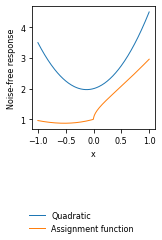

In [ ]:
# Define the assignment function separately from the original quadratic.
def f_assignment(x):
    # Clip negative inputs to zero before taking the square root.
    positive_x = np.maximum(x, 0)
    return 0.5 * x + np.sqrt(positive_x) - np.cos(x) + 2

# Compare the two true functions before fitting any models.
x_assignment = np.linspace(-x_max, x_max, 200)
fig, ax = plot_panels()
plt.plot(x_assignment, f_final(x_assignment), label='Quadratic')
plt.plot(x_assignment, f_assignment(x_assignment), label='Assignment function')
plt.xlabel('x')
plt.ylabel('Noise-free response')
fig.legend(loc='lower center', frameon=False)
plt.show()

# Next: change f_model = f_final to f_model = f_assignment in Cell 9 and rerun it.

## Full worked solution to the assignment

We answer all five questions: inspect the non-polynomial function, predict its bias from its features, compare it with the quadratic, increase the training sample size from 100 to 500, and plot a fitted polynomial of the selected degree for each sample size.

We retain the final experiment's other settings: a pool of 10,000 observations with inputs in $[-1,1]$, polynomial degrees 0 through 4, 1000 training experiments, noise standard deviation 1, and 100 test inputs sampled uniformly from $[0.5,1.5)$. Some test predictions therefore require **extrapolation**. The baseline uses 100 training observations.

The quadratic comparison uses `f_final`, the same quadratic as in the first part of the notebook. We change only the true function for the assignment baseline, then change only the sample size for Question 4.

The calculations below use explicit loops and a two-dimensional prediction table for one model degree at a time.

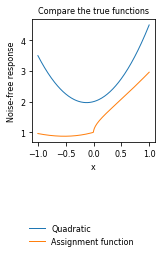

In [ ]:
# Question 1: define and plot the non-polynomial true function.
def g(x):
    # Take the maximum with zero separately for each input.
    positive_x = np.maximum(x, 0)
    return 0.5 * x + np.sqrt(positive_x) - np.cos(x) + 2

# Plot the true functions over the training interval.
solution_x = np.linspace(-1, 1, 200)
fig, ax = plot_panels()
ax.plot(solution_x, f_final(solution_x), label='Quadratic')
ax.plot(solution_x, g(solution_x), label='Assignment function')
ax.set_xlabel('x')
ax.set_ylabel('Noise-free response')
ax.set_title('Compare the true functions')
fig.legend(loc='lower center', frameon=False)
plt.show()


### Questions 1 and 2: shape and predicted bias

The assignment function is
$$
g(x)=0.5x+\sqrt{\max(x,0)}-\cos(x)+2.
$$
For negative inputs, the square-root term is zero. The function has a shallow minimum on the negative side and then increases toward $g(0)=1$. Just to the right of zero, the square-root term produces a very steep increase. The function is continuous, but it has no finite derivative at zero.

Every polynomial is smooth and has a finite derivative at zero. A polynomial therefore cannot reproduce that sharp change in slope exactly. The square-root and cosine terms also make $g$ non-polynomial. No polynomial of degree 0 through 4 can represent the whole function exactly, whereas degree 2 can represent our quadratic exactly.

We therefore predict **approximation bias** for the assignment function even when averaging over many training datasets. More training data can reduce sampling variability, but they do not change the set of functions the model can represent.

This prediction does not imply that $g$ has greater squared bias at every degree or input. A low-degree approximation to $g$ can be better than a low-degree approximation to the particular quadratic. Nor must increasing the degree reduce extrapolation bias: least squares optimizes the fit inside the training interval, not at test inputs beyond it.

In [ ]:
# Compare the quadratic, the assignment baseline, and the larger training set.
case_names = ['Quadratic', 'Assignment: baseline', 'Assignment: more data']
model_functions = [f_final, g, g]
train_sizes = [100, 100, 500]
noise_levels = [1, 1, 1]     # Keep the noise level fixed in every comparison.
n_cases = len(case_names)

degrees = [0, 1, 2, 3, 4]
pool_count = 10000
repeats = 1000
test_count = 100

# Share the input values and standard-normal noise across comparisons.
np.random.seed(1)
pool_x = np.random.uniform(-1, 1, pool_count)
pool_noise = np.random.normal(0, 1, pool_count)
test_x = np.random.uniform(0.5, 1.5, test_count)
test_noise = np.random.normal(0, 1, test_count)

# Store enough indices for the largest requested training set.
# The first 100 indices also give the paired smaller training set.
max_train_size = max(train_sizes)
training_sets = []
for r in range(repeats):
    training_sets.append(np.random.permutation(pool_count)[:max_train_size])

### Measure bias, variance, and error

Each row of a results table below represents one of the three cases; each column represents one polynomial degree. Within a case and degree, the prediction table has one row per experiment and one column per test input.

For each test input, we first average predictions over training experiments. We then calculate squared bias relative to the true function and variance around the mean prediction. Finally, we average those quantities over the test inputs.

We compare two errors:

- **Empirical test MSE:** prediction error against one fixed set of noisy test observations, averaged over experiments and test inputs.
- **Expected test MSE estimate:** estimated squared bias + estimated variance + noise variance.

The empirical and expected curves need not coincide, because the empirical calculation uses one finite realization of test noise. Repeating the training experiment does not replace that test-noise realization.

As in the preceding final experiment, the variability estimates here are conditional on one generated data pool. Using the same inputs, standardized noise, and training indices across cases helps isolate each change. It does not make the experiments noiseless or remove approximation bias.

In [ ]:
# Rows are cases; columns are polynomial degrees.
training_mse = np.zeros((n_cases, len(degrees)))
empirical_mse = np.zeros((n_cases, len(degrees)))
squared_bias = np.zeros((n_cases, len(degrees)))
prediction_variance = np.zeros((n_cases, len(degrees)))

for case in range(n_cases):
    true_function = model_functions[case]
    sample_size = train_sizes[case]
    sigma = noise_levels[case]

    # Change the true function while keeping inputs and noise fixed.
    pool_y = true_function(pool_x) + sigma * pool_noise
    true_test_y = true_function(test_x)
    noisy_test_y = true_test_y + sigma * test_noise

    for k in range(len(degrees)):
        d = degrees[k]
        predictions = np.zeros((repeats, test_count))
        training_errors = np.zeros(repeats)

        for r in range(repeats):
            # Select the requested 100 or 500 observations.
            idx = training_sets[r][:sample_size]
            train_x = pool_x[idx]
            train_y = pool_y[idx]

            # Fit the polynomial and evaluate its predictions.
            w = np.polyfit(train_x, train_y, d)
            fitted_train = np.polyval(w, train_x)
            predictions[r] = np.polyval(w, test_x)
            training_errors[r] = np.mean((train_y - fitted_train)**2)

        # Average across experiments at each test input.
        mean_curve = np.mean(predictions, axis=0)
        variance_curve = np.var(predictions, axis=0)

        # Average errors and components over all test inputs.
        training_mse[case, k] = np.mean(training_errors)
        empirical_mse[case, k] = np.mean((predictions - noisy_test_y)**2)
        squared_bias[case, k] = np.mean((mean_curve - true_test_y)**2)
        prediction_variance[case, k] = np.mean(variance_curve)

# Add the appropriate noise variance to each case.
expected_mse = squared_bias + prediction_variance
for case in range(n_cases):
    expected_mse[case] = expected_mse[case] + noise_levels[case]**2

### Question 3: compare the quadratic and non-polynomial examples

The first two panels change only the true function. The third uses the assignment function and increases its training sample size from 100 to 500, as requested in Question 4. The noise standard deviation remains 1 in all three cases.

All three panels use the same vertical scale for direct comparison. Each drawing area remains 1.7 inches wide, with 8-point text.

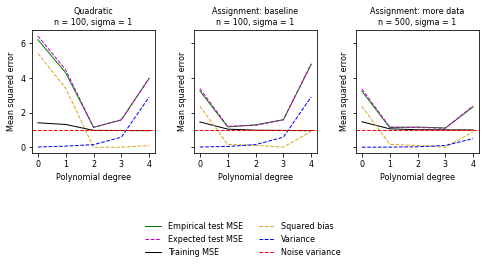

In [ ]:
# Show all three cases with the same curve colors as the final experiment.
fig, axs = plot_panels(1, 3, sharey=True)
for case in range(n_cases):
    ax = axs.flat[case]
    ax.plot(degrees, empirical_mse[case], color='green', label='Empirical test MSE')
    ax.plot(degrees, expected_mse[case], 'm--', label='Expected test MSE')
    ax.plot(degrees, training_mse[case], color='black', label='Training MSE')
    ax.plot(degrees, squared_bias[case], '--', color='goldenrod', label='Squared bias')
    ax.plot(degrees, prediction_variance[case], 'b--', label='Variance')
    ax.axhline(noise_levels[case]**2, color='red', linestyle='--', label='Noise variance')
    ax.set_xticks(degrees)
    ax.set_xlabel('Polynomial degree')
    ax.set_ylabel('Mean squared error')
    ax.set_title(f'{case_names[case]}\nn = {train_sizes[case]}, sigma = {noise_levels[case]}')

# One shared legend keeps the small drawing areas clear.
handles, labels = axs.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()

In [ ]:
# Print the numerical results so the curves can be checked degree by degree.
for case in range(n_cases):
    print(case_names[case])
    print('degree | bias^2 | variance | train MSE | test MSE | expected MSE')
    for k in range(len(degrees)):
        print(f'{degrees[k]:6d} | {squared_bias[case, k]:6.3f} | '
              f'{prediction_variance[case, k]:8.3f} | {training_mse[case, k]:9.3f} | '
              f'{empirical_mse[case, k]:8.3f} | {expected_mse[case, k]:12.3f}')
    print()

Quadratic
degree | bias^2 | variance | train MSE | test MSE | expected MSE
     0 |  5.420 |    0.014 |     1.414 |    6.218 |        6.433
     1 |  3.409 |    0.066 |     1.316 |    4.304 |        4.476
     2 |  0.000 |    0.149 |     0.976 |    1.152 |        1.150
     3 |  0.000 |    0.580 |     0.967 |    1.584 |        1.580
     4 |  0.097 |    2.906 |     0.957 |    3.986 |        4.003

Assignment: baseline
degree | bias^2 | variance | train MSE | test MSE | expected MSE
     0 |  2.377 |    0.014 |     1.461 |    3.258 |        3.390
     1 |  0.164 |    0.046 |     1.048 |    1.174 |        1.210
     2 |  0.114 |    0.150 |     0.985 |    1.298 |        1.264
     3 |  0.002 |    0.583 |     0.972 |    1.591 |        1.585
     4 |  0.923 |    2.911 |     0.959 |    4.778 |        4.834

Assignment: more data
degree | bias^2 | variance | train MSE | test MSE | expected MSE
     0 |  2.366 |    0.003 |     1.472 |    3.237 |        3.369
     1 |  0.165 |    0.009 |     1.

### Question 3: interpretation of the comparison

At degree 2, the quadratic has estimated squared bias **0.0004**, while the assignment function has estimated squared bias **0.1140**. The quadratic is correctly specified at this degree. Its small nonzero estimate reflects finite simulation and the particular finite data pool; the assignment function has model mismatch as well.

At degree 4, the assignment function has estimated squared bias **0.923** and variance **2.911**. A more flexible polynomial does not necessarily extrapolate better. The feature mismatch identified in Question 2 explains why approximation bias can remain, but it does not dictate a monotonic curve.

For the baseline assignment case, the smallest estimated expected test MSE among the tested degrees occurs at degree **1**, with value **1.210**. Its empirical test MSE is **1.174**. These values describe this fixed-seed simulation, not a universal best degree.

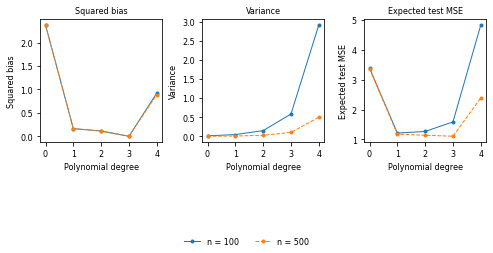

In [ ]:
# Question 4: compare n = 100 and n = 500, keeping sigma = 1.
fig, axs = plot_panels(1, 3)
quantities = [squared_bias, prediction_variance, expected_mse]
quantity_names = ['Squared bias', 'Variance', 'Expected test MSE']

for k in range(3):
    ax = axs[k]
    ax.plot(degrees, quantities[k][1], 'o-', label='n = 100')
    ax.plot(degrees, quantities[k][2], 'o--', label='n = 500')
    ax.set_xticks(degrees)
    ax.set_xlabel('Polynomial degree')
    ax.set_ylabel(quantity_names[k])
    ax.set_title(quantity_names[k])

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()

### Question 4: increasing the training sample size to 500

The training sample size increases fivefold, from **100 to 500 actual observations per fit**. The true function, noise standard deviation, training-input distribution, and test inputs remain fixed.

At degree 4, estimated variance changes from **2.911** to **0.499**, squared bias changes from **0.923** to **0.890**, and expected test MSE changes from **4.834** to **2.390**. Empirical test MSE changes from **4.778** to **2.335**.

The larger training sets stabilize the fitted coefficients, reducing variance and test error in this comparison. They do not make a polynomial capable of exactly representing the sharp change in slope and the non-polynomial terms in the true function. Estimated squared bias can change with sample size, but need not vanish or decrease at every degree. The noise variance remains **1**.

With 500 observations, the smallest estimated expected test MSE among the tested degrees occurs at degree **3**, with value **1.104**. This can differ from the best degree at 100 observations because the variance penalty for a more flexible fit is smaller.

### Question 4: select the polynomial degree for each sample size

We define "best" as the smallest **empirical held-out MSE, averaged over the training experiments**, among the tested degrees. We use row 1 for the assignment function with 100 observations and row 2 for the same function with 500 observations.

Because we now use the held-out observations to select a degree, they act as **validation data**, even though the earlier plots label their error as test MSE. A separate final test set would be needed to assess the selected model after this choice.

If multiple entries are exactly equal, `np.argmin` returns the first minimum; since the degree list is increasing, this selects the smallest tied degree. The selected degree need not be the best for every individual training dataset.


In [ ]:
# Choose the degree with the lowest empirical validation error for each size.
best_index_100 = np.argmin(empirical_mse[1])
best_index_500 = np.argmin(empirical_mse[2])
best_degree_100 = degrees[best_index_100]
best_degree_500 = degrees[best_index_500]

# Report the selected degrees and the errors used to select them.
print(f'n = 100: degree {best_degree_100}, '
      f'validation MSE = {empirical_mse[1, best_index_100]:.3f}')
print(f'n = 500: degree {best_degree_500}, '
      f'validation MSE = {empirical_mse[2, best_index_500]:.3f}')


n = 100: degree 1, validation MSE = 1.174
n = 500: degree 3, validation MSE = 1.110


### Question 5: fit the selected polynomials and compare them with $g(x)$

We use the **first paired training experiment** from the simulation to illustrate one fitted model for each sample size. Its 100-observation dataset consists of the first 100 indices of the same 500-observation dataset. The inputs and noisy responses are the ones already used in the assignment comparison, not newly generated data.

For each sample size, we fit its selected degree to the corresponding training data. We plot the fitted polynomial and the true function over $[-1,1.5]$, covering the training interval and the full validation range. The shaded region $x>1$ requires extrapolation.


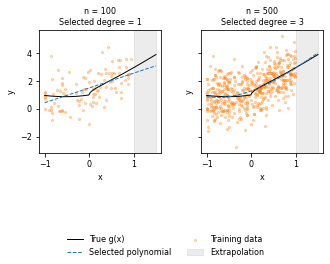

In [ ]:
# Use the assignment's noisy data pool, with noise standard deviation 1.
assignment_pool_y = g(pool_x) + noise_levels[1] * pool_noise
fit_sizes = [100, 500]
fit_degrees = [best_degree_100, best_degree_500]
fit_x = np.linspace(-1, 1.5, 300)

fig, axs = plot_panels(1, 2, sharey=True)
for k in range(2):
    # Reuse the corresponding data from the first training experiment.
    idx = training_sets[0][:fit_sizes[k]]
    train_x = pool_x[idx]
    train_y = assignment_pool_y[idx]

    # Fit the selected polynomial degree to these training observations.
    w = np.polyfit(train_x, train_y, fit_degrees[k])
    fitted_curve = np.polyval(w, fit_x)

    # Compare the fitted polynomial with the known true function.
    ax = axs[k]
    ax.plot(fit_x, g(fit_x), color='black', label='True g(x)')
    ax.plot(fit_x, fitted_curve, '--', color='tab:blue', label='Selected polynomial')
    ax.scatter(train_x, train_y, s=5, alpha=0.3,
               color='tab:orange', label='Training data')
    ax.axvspan(1, 1.5, color='gray', alpha=0.15, label='Extrapolation')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'n = {fit_sizes[k]}\nSelected degree = {fit_degrees[k]}')

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.show()


### Questions 4 and 5: selected degrees and fitted curves

For this fixed-seed simulation, the selected degrees are
$$
\hat d_{n=100}=1,\qquad \hat d_{n=500}=3.
$$
The corresponding mean empirical validation MSEs are **1.174** and **1.110**. These choices also minimize the estimated expected test MSE in this simulation, although those two criteria need not always agree.

The new figure shows one fit for each sample size using the first paired training experiment. Neither polynomial reproduces the sharp change in slope at zero exactly. The shaded region lies beyond the training interval, where a visually good fit to the training data does not guarantee accurate predictions.

The degrees were selected using average held-out error over 1000 training experiments. An individual fitted curve can look better or worse than that average suggests; this illustration does not claim that the chosen degree is optimal for every single training set or every input.

### What the revised assignment demonstrates

The sharp change in slope, square-root term, and cosine term make the assignment function incompatible with an exact low-degree polynomial representation. This can introduce approximation bias that the quadratic example does not have once degree 2 is available.

Increasing the training sample size from 100 to 500 can reduce variance and test error without removing the mismatch between the true function and the model class. The noise variance remains 1. Extrapolation can amplify both bias and variability, so the curves need not be monotonic.

The expected-error curve uses the known true function, which is available in this simulation. In an application we usually do not know that function and cannot measure bias directly. If these curves are used to select a degree, the selection data act as validation data; an independent final test set is needed to assess the selected model.

Selecting the degree using held-out error gives a concrete model for each sample size. Plotting a fit against the true function also shows where it succeeds or fails, including extrapolation; it does not replace independent final evaluation.
